In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/atharvaingle/crop-recommendation-dataset/Crop_recommendation.csv


In [2]:

# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob

# Find and load dataset

csv_files = glob.glob('/kaggle/input/**/*.csv', recursive=True)

print("Available CSV files:")
for file in csv_files:
    print(file)

df = pd.read_csv(csv_files[0])

print("\nDataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()


Available CSV files:
/kaggle/input/datasets/atharvaingle/crop-recommendation-dataset/Crop_recommendation.csv

Dataset loaded successfully!
Dataset Shape: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [3]:

# Display column names

print("COLUMN NAMES:")
print(df.columns.tolist())

# Display data types

print("\nDATA TYPES:")
print(df.dtypes)

# Separate features and target

X = df.drop('label', axis=1)
y = df['label']

print("\nFEATURES:")
print(X.columns.tolist())

print("\nTARGET:")
print(y.name)

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)


COLUMN NAMES:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

DATA TYPES:
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object

FEATURES:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

TARGET:
label

Feature Shape: (2200, 7)
Target Shape: (2200,)


In [4]:

# Check missing values

print("MISSING VALUES IN EACH COLUMN:")
print(df.isnull().sum())

print("\nTOTAL MISSING VALUES:")
print(df.isnull().sum().sum())

# Check duplicate rows

print("\nNUMBER OF DUPLICATE ROWS:")
print(df.duplicated().sum())


MISSING VALUES IN EACH COLUMN:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

TOTAL MISSING VALUES:
0

NUMBER OF DUPLICATE ROWS:
0


In [5]:

# Summary statistics

numerical_features = [
    'N', 'P', 'K',
    'temperature', 'humidity',
    'ph', 'rainfall'
]

print("SUMMARY STATISTICS:")
display(df[numerical_features].describe())

print("\nMEDIAN VALUES:")
display(df[numerical_features].median())

print("\nFEATURE RANGE:")
feature_range = (
    df[numerical_features].max() -
    df[numerical_features].min()
)
display(feature_range)

print("\nFEATURE WITH WIDEST RANGE:")
print(feature_range.idxmax())


SUMMARY STATISTICS:


,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117



MEDIAN VALUES:


N              37.000000
P              51.000000
K              32.000000
temperature    25.598693
humidity       80.473146
ph              6.425045
rainfall       94.867624
dtype: float64


FEATURE RANGE:


N              140.000000
P              140.000000
K              200.000000
temperature     34.849818
humidity        85.723836
ph               6.430338
rainfall       278.348850
dtype: float64


FEATURE WITH WIDEST RANGE:
rainfall


TOTAL UNIQUE CROPS: 22

LIST OF CROPS:
apple
banana
blackgram
chickpea
coconut
coffee
cotton
grapes
jute
kidneybeans
lentil
maize
mango
mothbeans
mungbean
muskmelon
orange
papaya
pigeonpeas
pomegranate
rice
watermelon

SAMPLES PER CROP:


label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64

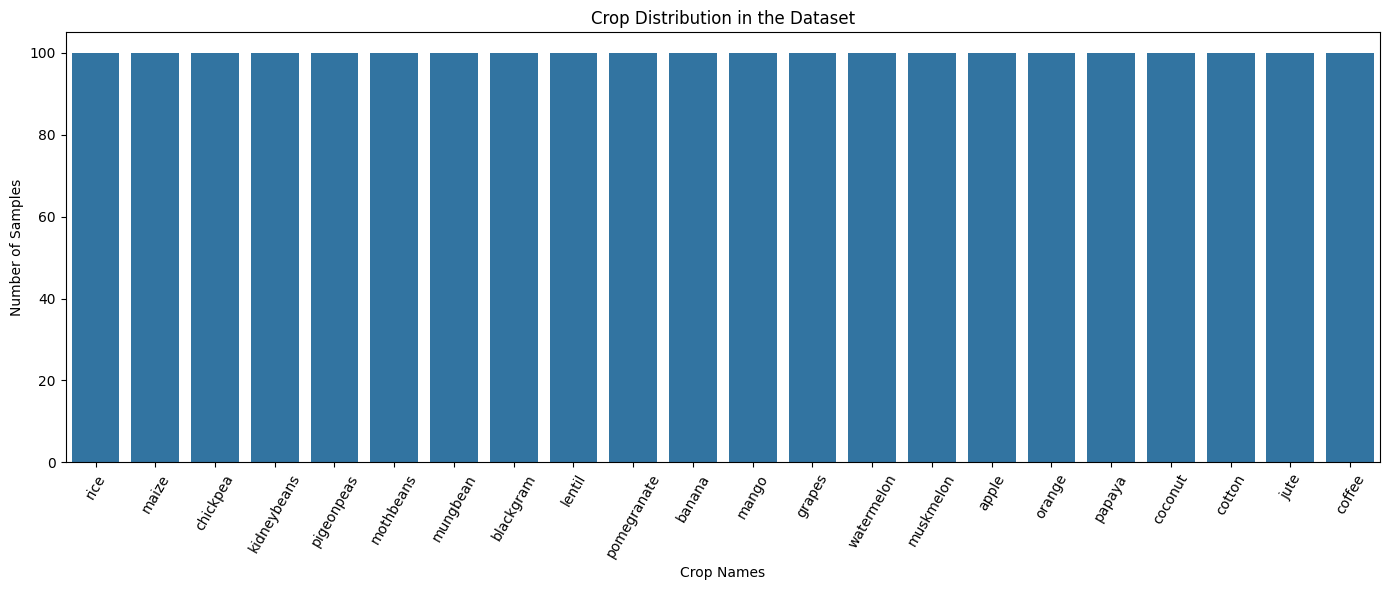

Maximum samples: 100
Minimum samples: 100
Dataset is perfectly balanced.


In [6]:

# Find unique crop categories

unique_crops = df['label'].unique()

print("TOTAL UNIQUE CROPS:", df['label'].nunique())

print("\nLIST OF CROPS:")
for crop in sorted(unique_crops):
    print(crop)

# Count samples per crop

crop_counts = df['label'].value_counts()

print("\nSAMPLES PER CROP:")
display(crop_counts)

# Visualize crop distribution

plt.figure(figsize=(14, 6))

sns.countplot(
    data=df,
    x='label',
    order=df['label'].value_counts().index
)

plt.title("Crop Distribution in the Dataset")
plt.xlabel("Crop Names")
plt.ylabel("Number of Samples")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

# Check class balance

print("Maximum samples:", crop_counts.max())
print("Minimum samples:", crop_counts.min())

if crop_counts.max() == crop_counts.min():
    print("Dataset is perfectly balanced.")
else:
    print("Dataset is not perfectly balanced.")


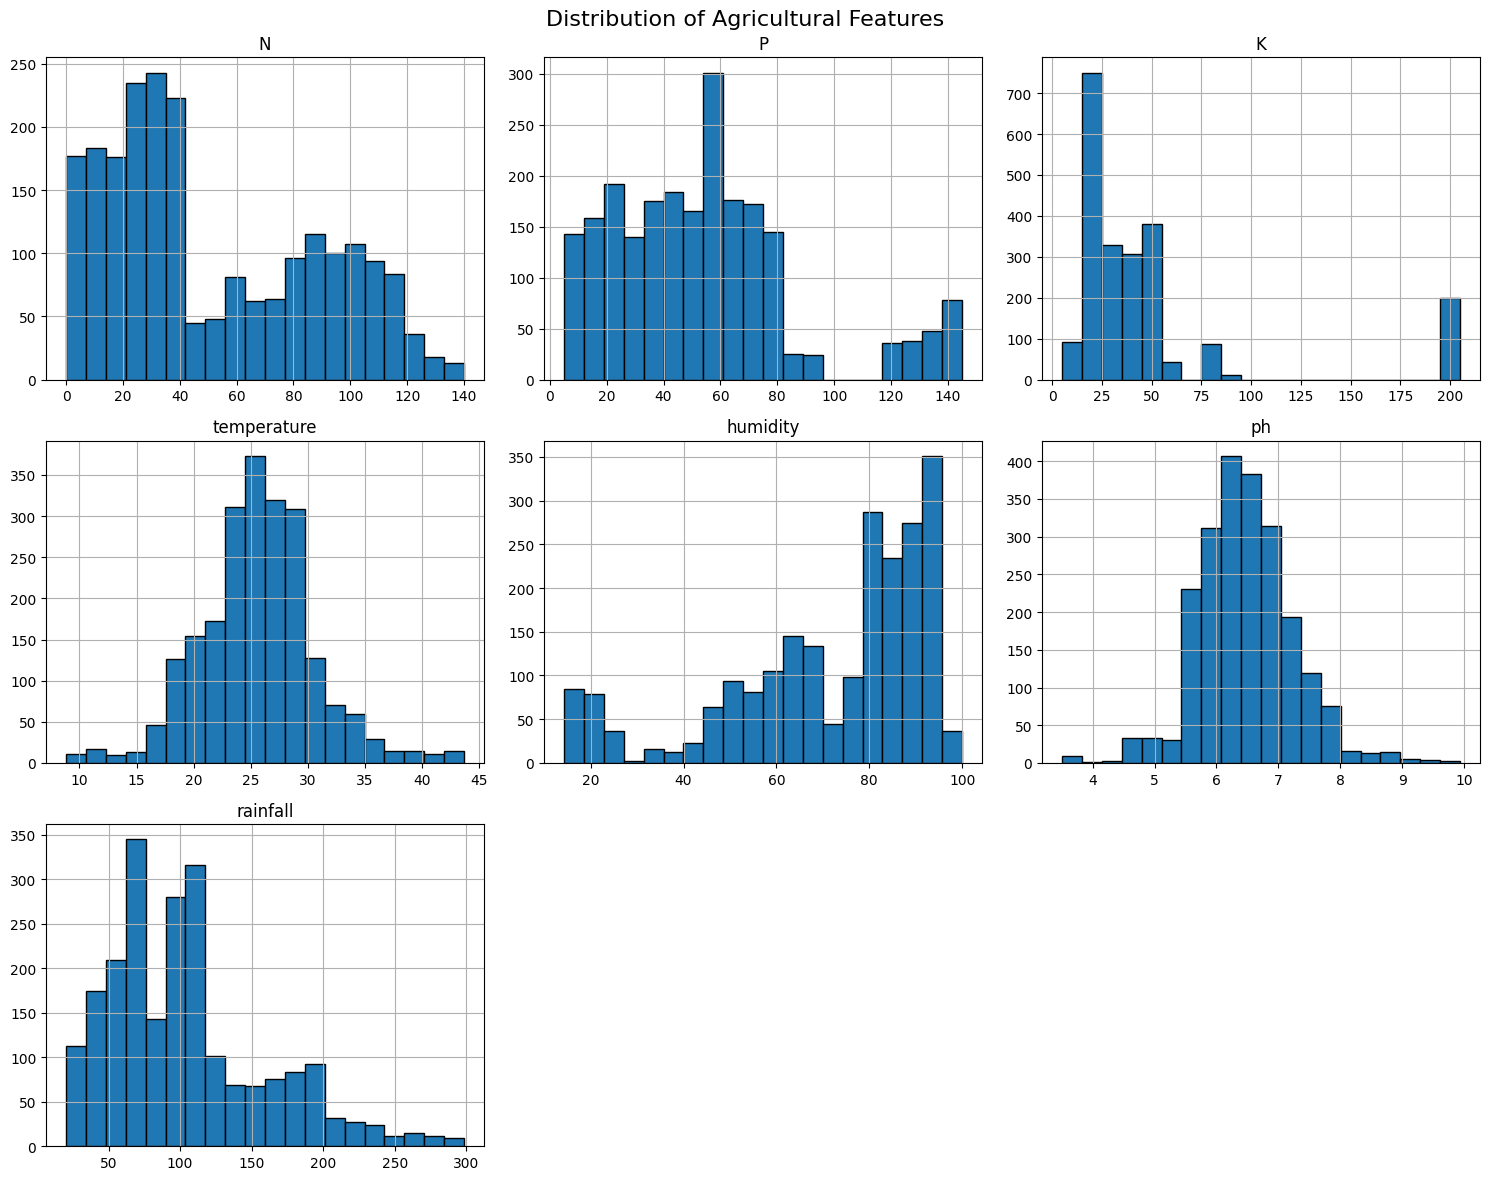

SKEWNESS OF EACH FEATURE:


,Skewness
N,0.509721
P,1.010773
K,2.375167
temperature,0.184933
humidity,-1.091708
ph,0.283929
rainfall,0.965756


N : Right-skewed
P : Right-skewed
K : Right-skewed
temperature : Approximately symmetric
humidity : Left-skewed
ph : Approximately symmetric
rainfall : Right-skewed


In [7]:

# Plot histograms for all numerical features

df[numerical_features].hist(
    figsize=(15, 12),
    bins=20,
    edgecolor='black'
)

plt.suptitle(
    "Distribution of Agricultural Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Calculate skewness

skew_values = df[numerical_features].skew()

print("SKEWNESS OF EACH FEATURE:")
display(skew_values.to_frame("Skewness"))

# Interpret skewness

for feature, value in skew_values.items():

    if value > 0.5:
        result = "Right-skewed"

    elif value < -0.5:
        result = "Left-skewed"

    else:
        result = "Approximately symmetric"

    print(feature, ":", result)


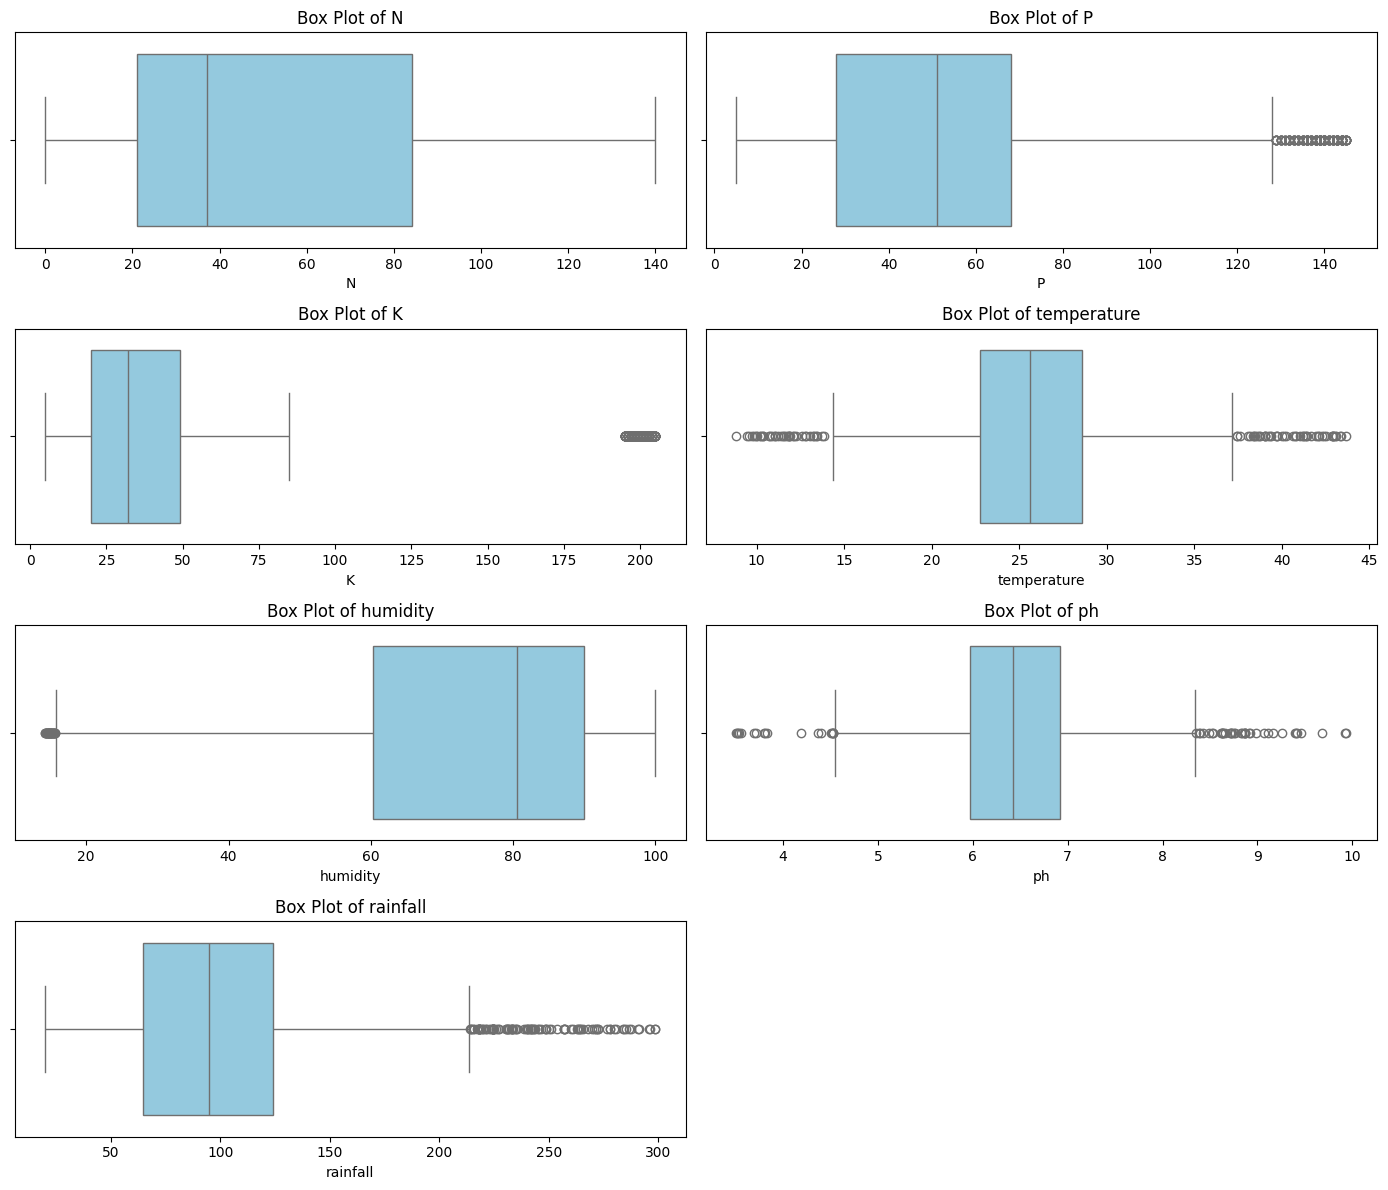

In [8]:

# Q7: Box plots for all numerical features

plt.figure(figsize=(14, 12))

for i, feature in enumerate(numerical_features, 1):

    plt.subplot(4, 2, i)

    sns.boxplot(
        x=df[feature],
        color='skyblue'
    )

    plt.title(f'Box Plot of {feature}')
    plt.xlabel(feature)

plt.tight_layout()
plt.show()


In [10]:

# Calculate outliers using IQR method

for feature in numerical_features:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ]

    print("----------------------------------")
    print("Feature:", feature)
    print("Q1:", round(Q1, 2))
    print("Q3:", round(Q3, 2))
    print("IQR:", round(IQR, 2))
    print("Lower Bound:", round(lower_bound, 2))
    print("Upper Bound:", round(upper_bound, 2))
    print("Number of Outliers:", len(outliers))


----------------------------------
Feature: N
Q1: 21.0
Q3: 84.25
IQR: 63.25
Lower Bound: -73.88
Upper Bound: 179.12
Number of Outliers: 0
----------------------------------
Feature: P
Q1: 28.0
Q3: 68.0
IQR: 40.0
Lower Bound: -32.0
Upper Bound: 128.0
Number of Outliers: 138
----------------------------------
Feature: K
Q1: 20.0
Q3: 49.0
IQR: 29.0
Lower Bound: -23.5
Upper Bound: 92.5
Number of Outliers: 200
----------------------------------
Feature: temperature
Q1: 22.77
Q3: 28.56
IQR: 5.79
Lower Bound: 14.08
Upper Bound: 37.25
Number of Outliers: 86
----------------------------------
Feature: humidity
Q1: 60.26
Q3: 89.95
IQR: 29.69
Lower Bound: 15.73
Upper Bound: 134.48
Number of Outliers: 30
----------------------------------
Feature: ph
Q1: 5.97
Q3: 6.92
IQR: 0.95
Lower Bound: 4.54
Upper Bound: 8.35
Number of Outliers: 57
----------------------------------
Feature: rainfall
Q1: 64.55
Q3: 124.27
IQR: 59.72
Lower Bound: -25.02
Upper Bound: 213.84
Number of Outliers: 100


In [11]:

# Summary of outliers across all features

outlier_results = []

for feature in numerical_features:

    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (df[feature] < lower) |
        (df[feature] > upper)
    ).sum()

    outlier_results.append({
        'Feature': feature,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Outlier Count': count
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df.round(2))


,Feature,Q1,Q3,IQR,Outlier Count
0,N,21.00,84.25,63.25,0
1,P,28.00,68.00,40.00,138
2,K,20.00,49.00,29.00,200
3,temperature,22.77,28.56,5.79,86
4,humidity,60.26,89.95,29.69,30
5,ph,5.97,6.92,0.95,57
6,rainfall,64.55,124.27,59.72,100


In [12]:

# Q8: Calculate correlation matrix

correlation_matrix = df[numerical_features].corr()

print("CORRELATION MATRIX:")
display(correlation_matrix.round(2))


CORRELATION MATRIX:


,N,P,K,temperature,humidity,ph,rainfall
N,1.00,-0.23,-0.14,0.03,0.19,0.10,0.06
P,-0.23,1.00,0.74,-0.13,-0.12,-0.14,-0.06
K,-0.14,0.74,1.00,-0.16,0.19,-0.17,-0.05
temperature,0.03,-0.13,-0.16,1.00,0.21,-0.02,-0.03
humidity,0.19,-0.12,0.19,0.21,1.00,-0.01,0.09
ph,0.10,-0.14,-0.17,-0.02,-0.01,1.00,-0.11
rainfall,0.06,-0.06,-0.05,-0.03,0.09,-0.11,1.00


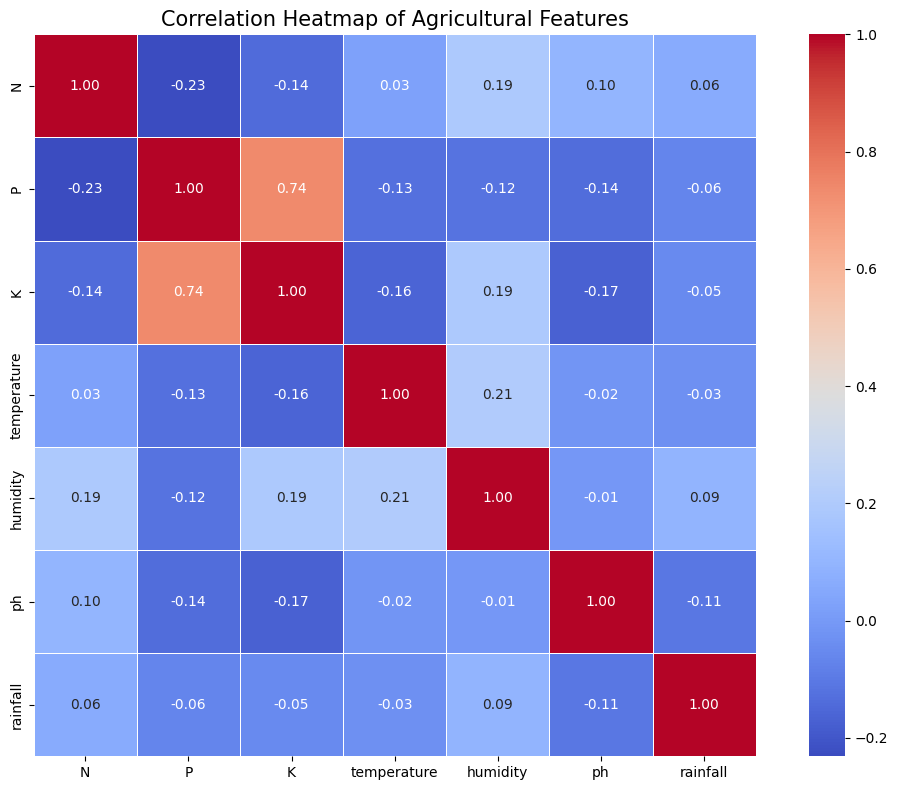

In [13]:

# Q8: Correlation Heatmap

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    square=True
)

plt.title("Correlation Heatmap of Agricultural Features",
          fontsize=15)

plt.tight_layout()
plt.show()


In [14]:

# Find strongest feature correlations

corr_pairs = correlation_matrix.unstack()

# Remove self-correlations and duplicate pairs
corr_pairs = corr_pairs[
    corr_pairs.index.get_level_values(0) !=
    corr_pairs.index.get_level_values(1)
]

corr_pairs = corr_pairs.reset_index()
corr_pairs.columns = ['Feature 1', 'Feature 2', 'Correlation']

# Keep only unique pairs
corr_pairs['Pair'] = corr_pairs.apply(
    lambda row: tuple(sorted([row['Feature 1'], row['Feature 2']])),
    axis=1
)

corr_pairs = corr_pairs.drop_duplicates(subset='Pair')

# Strongest positive and negative correlations
print("STRONGEST POSITIVE CORRELATION:")
display(corr_pairs.sort_values(
    'Correlation', ascending=False
).head(5))

print("STRONGEST NEGATIVE CORRELATION:")
display(corr_pairs.sort_values(
    'Correlation', ascending=True
).head(5))


STRONGEST POSITIVE CORRELATION:


,Feature 1,Feature 2,Correlation,Pair
7,P,K,0.736232,"(K, P)"
21,temperature,humidity,0.205320,"(humidity, temperature)"
15,K,humidity,0.190859,"(K, humidity)"
3,N,humidity,0.190688,"(N, humidity)"
4,N,ph,0.096683,"(N, ph)"


STRONGEST NEGATIVE CORRELATION:


,Feature 1,Feature 2,Correlation,Pair
0,N,P,-0.231460,"(N, P)"
16,K,ph,-0.169503,"(K, ph)"
14,K,temperature,-0.160387,"(K, temperature)"
1,N,K,-0.140512,"(K, N)"
10,P,ph,-0.138019,"(P, ph)"


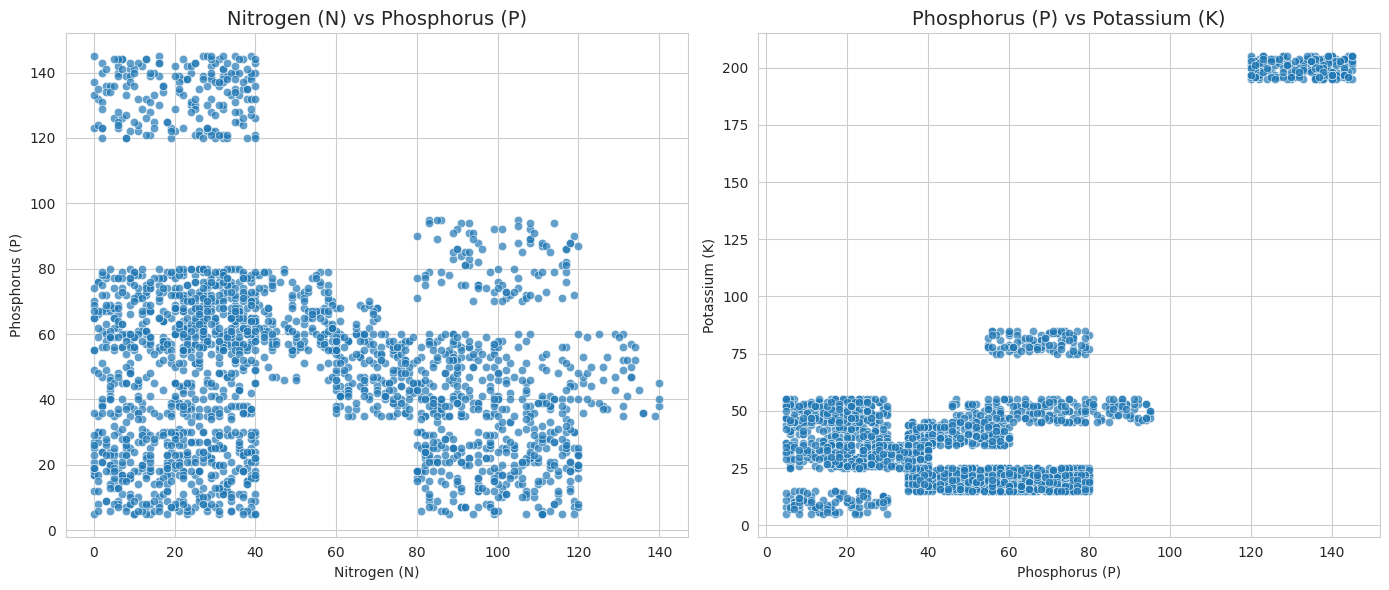

In [15]:
# Q9: Scatter Plot Analysis - N vs P and P vs K

import matplotlib.pyplot as plt
import seaborn as sns

# Set the plot style
sns.set_style("whitegrid")

# Create a figure with two side-by-side scatter plots
plt.figure(figsize=(14, 6))

# Scatter plot 1: Nitrogen vs Phosphorus
plt.subplot(1, 2, 1)

sns.scatterplot(
    data=df,
    x='N',
    y='P',
    alpha=0.7
)

plt.title('Nitrogen (N) vs Phosphorus (P)', fontsize=14)
plt.xlabel('Nitrogen (N)')
plt.ylabel('Phosphorus (P)')

# Scatter plot 2: Phosphorus vs Potassium
plt.subplot(1, 2, 2)

sns.scatterplot(
    data=df,
    x='P',
    y='K',
    alpha=0.7
)

plt.title('Phosphorus (P) vs Potassium (K)', fontsize=14)
plt.xlabel('Phosphorus (P)')
plt.ylabel('Potassium (K)')

# Adjust spacing and display plots
plt.tight_layout()
plt.show()

In [16]:

# Q10: Calculate average agricultural conditions for each crop

# Select the numerical features
numerical_features = [
    'N', 'P', 'K',
    'temperature', 'humidity',
    'ph', 'rainfall'
]

# Group the dataset by crop label and calculate the mean
crop_averages = df.groupby('label')[numerical_features].mean()

# Display the average values
print("AVERAGE AGRICULTURAL CONDITIONS FOR EACH CROP:")
display(crop_averages.round(2))

# Optional: Display the result as a normal DataFrame
crop_averages = crop_averages.reset_index()


AVERAGE AGRICULTURAL CONDITIONS FOR EACH CROP:


,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
apple,20.80,134.22,199.89,22.63,92.33,5.93,112.65
banana,100.23,82.01,50.05,27.38,80.36,5.98,104.63
blackgram,40.02,67.47,19.24,29.97,65.12,7.13,67.88
chickpea,40.09,67.79,79.92,18.87,16.86,7.34,80.06
coconut,21.98,16.93,30.59,27.41,94.84,5.98,175.69
coffee,101.20,28.74,29.94,25.54,58.87,6.79,158.07
cotton,117.77,46.24,19.56,23.99,79.84,6.91,80.40
grapes,23.18,132.53,200.11,23.85,81.88,6.03,69.61
jute,78.40,46.86,39.99,24.96,79.64,6.73,174.79


In [17]:

# Q11: Find 3 crops with highest and lowest average rainfall

rainfall_avg = df.groupby('label')['rainfall'].mean()

sorted_rainfall = rainfall_avg.sort_values(ascending=False)

print("TOP 3 CROPS WITH HIGHEST RAINFALL:")
display(sorted_rainfall.head(3).round(2))

print("TOP 3 CROPS WITH LOWEST RAINFALL:")
display(sorted_rainfall.tail(3).sort_values().round(2))


TOP 3 CROPS WITH HIGHEST RAINFALL:


label
rice       236.18
coconut    175.69
jute       174.79
Name: rainfall, dtype: float64

TOP 3 CROPS WITH LOWEST RAINFALL:


label
muskmelon    24.69
lentil       45.68
mungbean     48.40
Name: rainfall, dtype: float64

In [18]:

# Q12: Find crops with highest and lowest average temperature

temperature_avg = df.groupby('label')['temperature'].mean()

sorted_temperature = temperature_avg.sort_values(ascending=False)

print("CROPS WITH HIGHEST AVERAGE TEMPERATURE:")
display(sorted_temperature.head(3).round(2))

print("CROPS WITH LOWEST AVERAGE TEMPERATURE:")
display(sorted_temperature.tail(3).sort_values().round(2))


CROPS WITH HIGHEST AVERAGE TEMPERATURE:


label
papaya       33.72
mango        31.21
blackgram    29.97
Name: temperature, dtype: float64

CROPS WITH LOWEST AVERAGE TEMPERATURE:


label
chickpea       18.87
kidneybeans    20.12
pomegranate    21.84
Name: temperature, dtype: float64

In [19]:

# Q13: Identify crops growing in acidic and alkaline soil

acidic_crops = df[df['ph'] < 6]['label'].unique()

alkaline_crops = df[df['ph'] > 7.5]['label'].unique()

print("CROPS GROWING IN ACIDIC SOIL (pH < 6):")
print(sorted(acidic_crops))

print("\nCROPS GROWING IN ALKALINE SOIL (pH > 7.5):")
print(sorted(alkaline_crops))


CROPS GROWING IN ACIDIC SOIL (pH < 6):
['apple', 'banana', 'chickpea', 'coconut', 'cotton', 'grapes', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'pigeonpeas', 'pomegranate', 'rice']

CROPS GROWING IN ALKALINE SOIL (pH > 7.5):
['blackgram', 'chickpea', 'cotton', 'lentil', 'mothbeans', 'orange', 'rice']


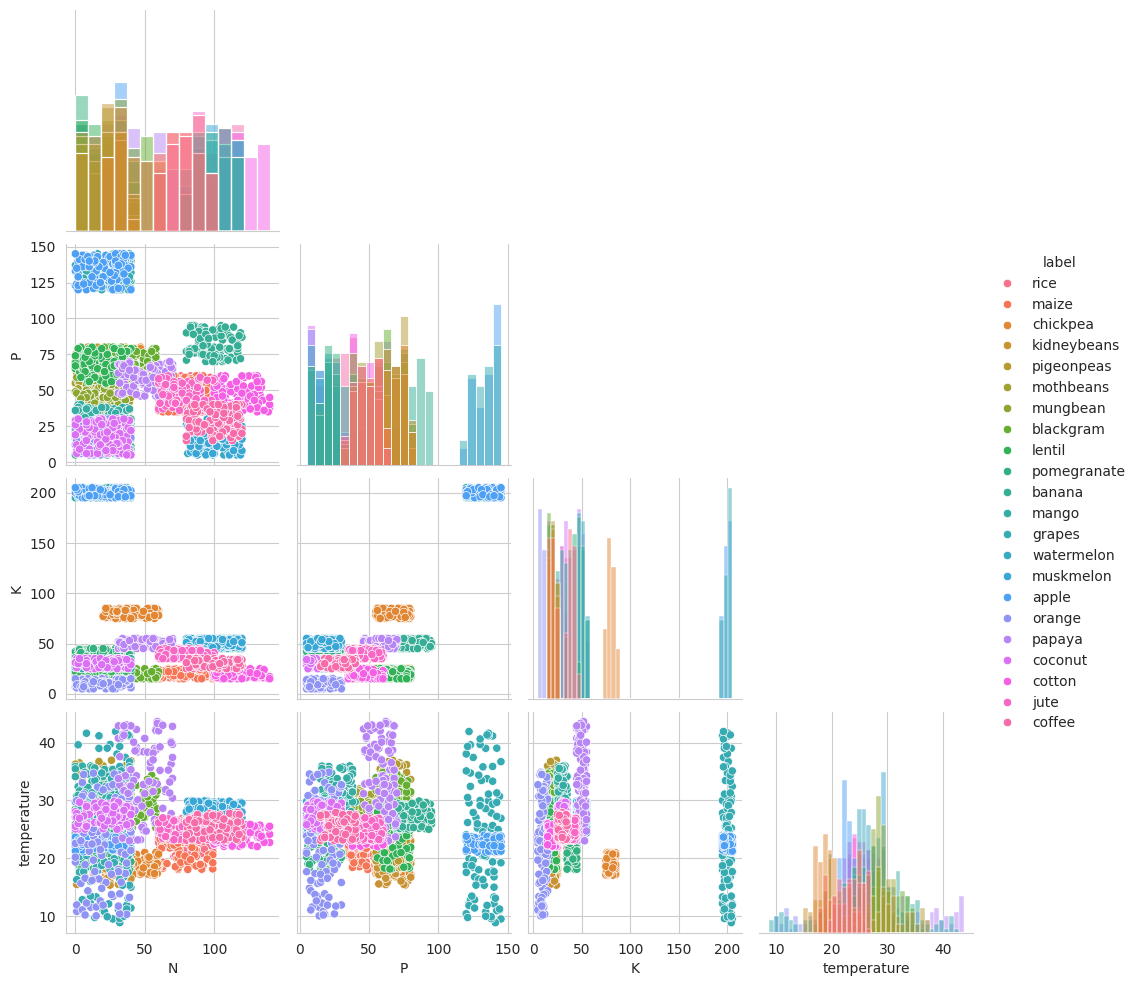

In [20]:

# Q14: Pair plot of four numerical features

import seaborn as sns
import matplotlib.pyplot as plt

selected_features = ['N', 'P', 'K', 'temperature']

sns.pairplot(
    df,
    vars=selected_features,
    hue='label',
    diag_kind='hist',
    corner=True
)

plt.show()


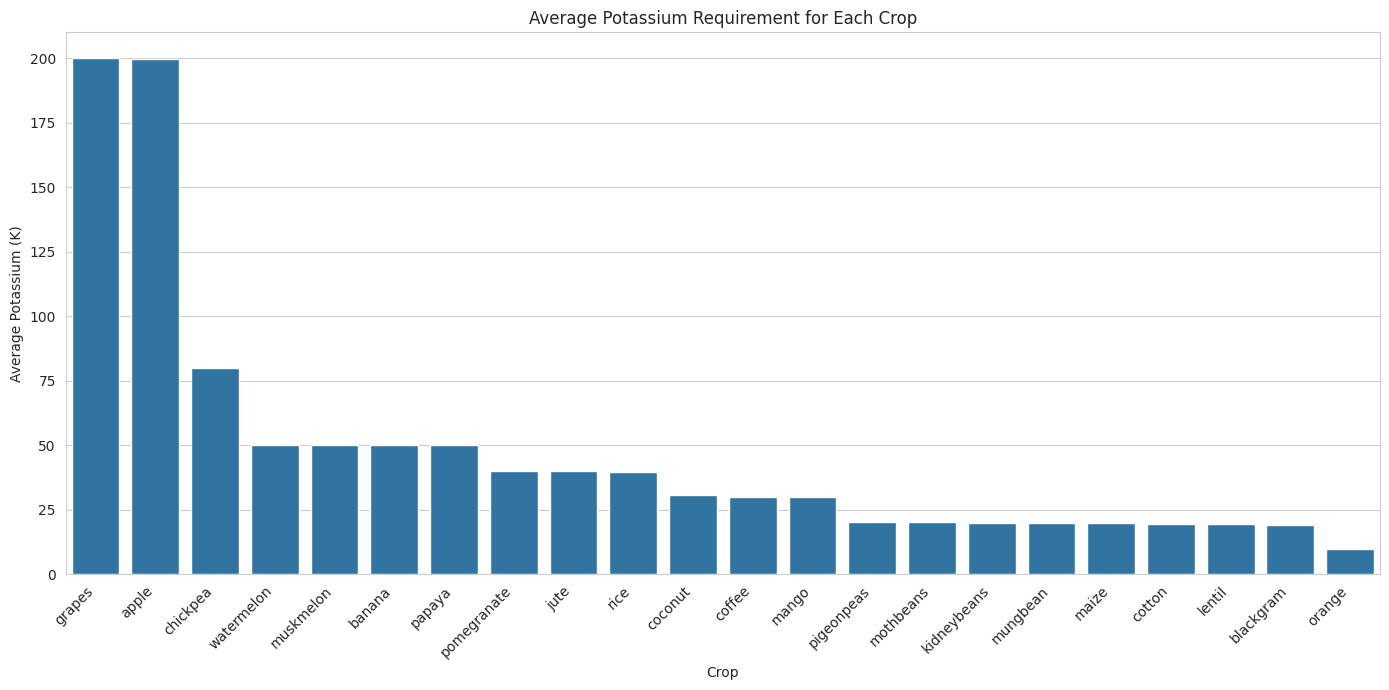

CROPS WITH HIGHEST POTASSIUM REQUIREMENTS:


label
grapes        200.11
apple         199.89
chickpea       79.92
watermelon     50.22
muskmelon      50.08
Name: K, dtype: float64

In [21]:

# Q15: Average potassium requirement for each crop

import matplotlib.pyplot as plt
import seaborn as sns

potassium_avg = df.groupby('label')['K'].mean()

potassium_avg = potassium_avg.sort_values(ascending=False)

plt.figure(figsize=(14, 7))

sns.barplot(
    x=potassium_avg.index,
    y=potassium_avg.values
)

plt.title('Average Potassium Requirement for Each Crop')
plt.xlabel('Crop')
plt.ylabel('Average Potassium (K)')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

print("CROPS WITH HIGHEST POTASSIUM REQUIREMENTS:")
display(potassium_avg.head(5).round(2))


In [22]:
import pandas as pd

# Keep the original dataset unchanged
df_clean = df.copy()

# Select numerical feature columns
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']

# Identify outliers using IQR
outlier_mask = pd.Series(False, index=df_clean.index)

for col in features:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    column_outliers = (
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    )

    print(f"{col}: {column_outliers.sum()} outliers")

    outlier_mask = outlier_mask | column_outliers

# Count unique rows containing at least one outlier
affected_rows = outlier_mask.sum()

# Remove affected rows
df_clean = df_clean.loc[~outlier_mask].copy()

print("\nTotal rows affected:", affected_rows)
print("Rows before handling:", len(df))
print("Rows after handling:", len(df_clean))

N: 0 outliers
P: 138 outliers
K: 200 outliers
temperature: 86 outliers
humidity: 30 outliers
ph: 57 outliers
rainfall: 100 outliers

Total rows affected: 432
Rows before handling: 2200
Rows after handling: 1768


In [23]:
from sklearn.preprocessing import LabelEncoder

# Create the label encoder
label_encoder = LabelEncoder()

# Encode crop names into numerical values
df_clean['label_encoded'] = label_encoder.fit_transform(df_clean['label'])

# Display crop-to-number mapping
crop_mapping = dict(zip(label_encoder.classes_,
                        label_encoder.transform(label_encoder.classes_)))

print("Crop Label Mapping:")
print(crop_mapping)

# Display original and encoded labels
display(df_clean[['label', 'label_encoded']].head(10))

print("\nNumber of unique crop classes:", len(label_encoder.classes_))

Crop Label Mapping:
{'banana': np.int64(0), 'blackgram': np.int64(1), 'chickpea': np.int64(2), 'coconut': np.int64(3), 'coffee': np.int64(4), 'cotton': np.int64(5), 'jute': np.int64(6), 'kidneybeans': np.int64(7), 'lentil': np.int64(8), 'maize': np.int64(9), 'mango': np.int64(10), 'mothbeans': np.int64(11), 'mungbean': np.int64(12), 'muskmelon': np.int64(13), 'orange': np.int64(14), 'papaya': np.int64(15), 'pigeonpeas': np.int64(16), 'pomegranate': np.int64(17), 'rice': np.int64(18), 'watermelon': np.int64(19)}


,label,label_encoded
0,rice,18
13,rice,18
14,rice,18
17,rice,18
20,rice,18
22,rice,18
29,rice,18
31,rice,18
35,rice,18
41,rice,18



Number of unique crop classes: 20


In [24]:
from sklearn.preprocessing import LabelEncoder

# Create label encoder
le = LabelEncoder()

# Encode crop labels
df_clean['label_encoded'] = le.fit_transform(df_clean['label'])

# Display original and encoded labels
print("Crop Label Encoding:")
for crop, encoded_value in zip(le.classes_, le.transform(le.classes_)):
    print(f"{crop}: {encoded_value}")

# Display first few rows
display(df_clean[['label', 'label_encoded']].head())

print("\nNumber of unique crops:", len(le.classes_))

Crop Label Encoding:
banana: 0
blackgram: 1
chickpea: 2
coconut: 3
coffee: 4
cotton: 5
jute: 6
kidneybeans: 7
lentil: 8
maize: 9
mango: 10
mothbeans: 11
mungbean: 12
muskmelon: 13
orange: 14
papaya: 15
pigeonpeas: 16
pomegranate: 17
rice: 18
watermelon: 19


,label,label_encoded
0,rice,18
13,rice,18
14,rice,18
17,rice,18
20,rice,18



Number of unique crops: 20


In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Select input features and target
X = df_clean[['N', 'P', 'K', 'temperature',
              'humidity', 'ph', 'rainfall']]

y = df_clean['label_encoded']

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Apply feature scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Display dataset shapes
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining percentage:",
      round(len(X_train) / len(df_clean) * 100, 2), "%")

print("Testing percentage:",
      round(len(X_test) / len(df_clean) * 100, 2), "%")

Training data shape: (1414, 7)
Testing data shape: (354, 7)

Training target shape: (1414,)
Testing target shape: (354,)

Training percentage: 79.98 %
Testing percentage: 20.02 %


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Initialize Logistic Regression model
log_model = LogisticRegression(max_iter=2000, random_state=42)

# Train the model
log_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_log = log_model.predict(X_test_scaled)

# Calculate accuracy
log_accuracy = accuracy_score(y_test, y_pred_log)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print("Accuracy:", round(log_accuracy * 100, 2), "%")

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 96.05 %


In [28]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)

y_pred_dt = dt_model.predict(X_test_scaled)
dt_accuracy = accuracy_score(y_test, y_pred_dt)

# KNN
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)
knn_accuracy = accuracy_score(y_test, y_pred_knn)

# Display results
print("DECISION TREE ACCURACY:", round(dt_accuracy * 100, 2), "%")
print("KNN ACCURACY:", round(knn_accuracy * 100, 2), "%")

DECISION TREE ACCURACY: 99.72 %
KNN ACCURACY: 96.61 %


In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test_scaled)

# Calculate accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("RANDOM FOREST RESULTS")
print("---------------------")
print("Accuracy:", round(rf_accuracy * 100, 2), "%")

RANDOM FOREST RESULTS
---------------------
Accuracy: 99.44 %


<Figure size 1400x1200 with 0 Axes>

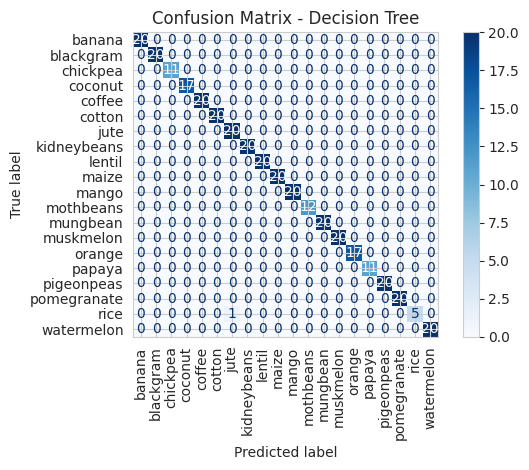

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_dt)

# Display confusion matrix
plt.figure(figsize=(14, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le.classes_
)

disp.plot(
    cmap='Blues',
    xticks_rotation=90,
    values_format='d'
)

plt.title("Confusion Matrix - Decision Tree")
plt.tight_layout()
plt.show()

In [31]:
from sklearn.metrics import classification_report

print("CLASSIFICATION REPORT - DECISION TREE")
print("-------------------------------------")

print(classification_report(
    y_test,
    y_pred_dt,
    target_names=le.classes_
))

CLASSIFICATION REPORT - DECISION TREE
-------------------------------------
              precision    recall  f1-score   support

      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        11
     coconut       1.00      1.00      1.00        17
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        12
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        17
      papaya       1.00      1.00      1.00        11
  pig

In [32]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
import numpy as np

# Initialize Decision Tree
dt_cv_model = DecisionTreeClassifier(random_state=42)

# Initialize 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Perform cross-validation
cv_scores = cross_val_score(
    dt_cv_model,
    X_train_scaled,
    y_train,
    cv=cv,
    scoring='accuracy'
)

# Display results
print("5-FOLD CROSS-VALIDATION RESULTS")
print("--------------------------------")

for i, score in enumerate(cv_scores, start=1):
    print(f"Fold {i} Accuracy: {score * 100:.2f}%")

print("\nMean Accuracy:", round(np.mean(cv_scores) * 100, 2), "%")
print("Standard Deviation:", round(np.std(cv_scores) * 100, 2), "%")

5-FOLD CROSS-VALIDATION RESULTS
--------------------------------
Fold 1 Accuracy: 97.17%
Fold 2 Accuracy: 97.88%
Fold 3 Accuracy: 96.47%
Fold 4 Accuracy: 98.23%
Fold 5 Accuracy: 98.58%

Mean Accuracy: 97.67 %
Standard Deviation: 0.76 %


FEATURE IMPORTANCE:


,Feature,Importance
6,rainfall,0.234884
4,humidity,0.214997
2,K,0.154507
1,P,0.136540
0,N,0.121420
3,temperature,0.083596
5,ph,0.054056


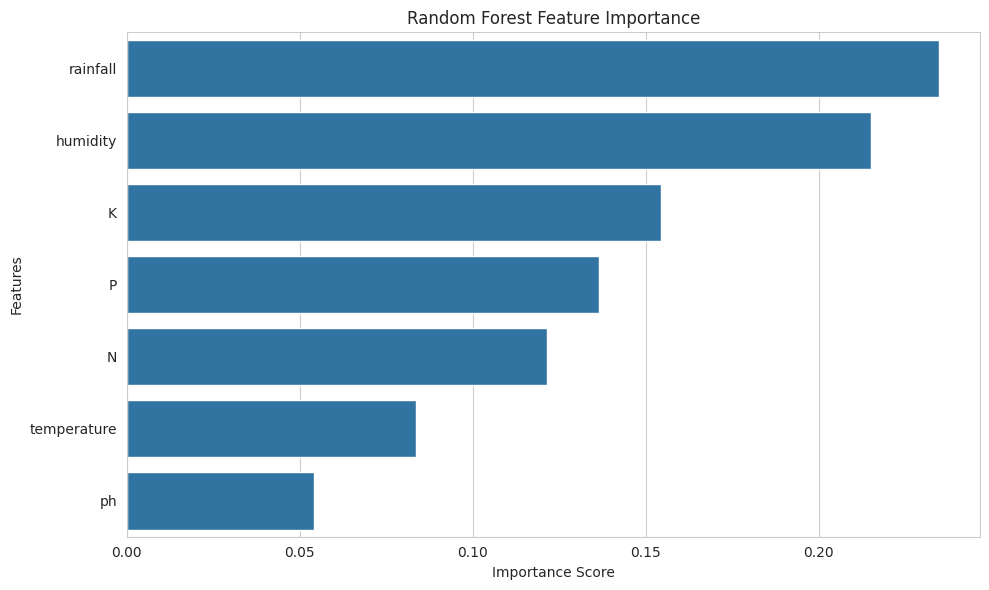

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importance
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("FEATURE IMPORTANCE:")
display(feature_importance)

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [34]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Remove the least important feature: ph
selected_features = [
    'N', 'P', 'K', 'temperature', 'humidity', 'rainfall'
]

# Create reduced datasets
X_train_reduced = X_train[selected_features]
X_test_reduced = X_test[selected_features]

# Scale the reduced features
from sklearn.preprocessing import StandardScaler

scaler_reduced = StandardScaler()

X_train_reduced_scaled = scaler_reduced.fit_transform(X_train_reduced)
X_test_reduced_scaled = scaler_reduced.transform(X_test_reduced)

# Train Decision Tree with reduced features
dt_reduced = DecisionTreeClassifier(random_state=42)

dt_reduced.fit(X_train_reduced_scaled, y_train)

# Predict
y_pred_reduced = dt_reduced.predict(X_test_reduced_scaled)

# Calculate accuracy
reduced_accuracy = accuracy_score(y_test, y_pred_reduced)

print("FEATURE SELECTION RESULTS")
print("-------------------------")
print("Original Features:", X_train.shape[1])
print("Reduced Features:", len(selected_features))

print("\nOriginal Decision Tree Accuracy:",
      round(dt_accuracy * 100, 2), "%")

print("Reduced Decision Tree Accuracy:",
      round(reduced_accuracy * 100, 2), "%")

FEATURE SELECTION RESULTS
-------------------------
Original Features: 7
Reduced Features: 6

Original Decision Tree Accuracy: 99.72 %
Reduced Decision Tree Accuracy: 98.87 %


In [35]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# Initialize Decision Tree
dt = DecisionTreeClassifier(random_state=42)

# Define hyperparameter combinations
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 10, 15, 20, 25],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Initialize Grid Search
grid_search = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Perform hyperparameter tuning
grid_search.fit(X_train_scaled, y_train)

# Get best model
best_dt_model = grid_search.best_estimator_

# Predict using the tuned model
y_pred_tuned = best_dt_model.predict(X_test_scaled)

# Calculate test accuracy
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

# Display results
print("HYPERPARAMETER TUNING RESULTS")
print("-----------------------------")
print("Best Parameters:", grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:",
      round(grid_search.best_score_ * 100, 2), "%")

print("Tuned Model Test Accuracy:",
      round(tuned_accuracy * 100, 2), "%")

HYPERPARAMETER TUNING RESULTS
-----------------------------
Best Parameters: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}

Best Cross-Validation Accuracy: 98.44 %
Tuned Model Test Accuracy: 98.87 %


In [36]:
import pandas as pd

# Input values
new_data = pd.DataFrame([{
    'N': 90,
    'P': 42,
    'K': 43,
    'temperature': 21,
    'humidity': 82,
    'ph': 6.5,
    'rainfall': 203
}])

# Apply the same scaler used during training
new_data_scaled = scaler.transform(new_data)

# Predict crop
prediction = dt_model.predict(new_data_scaled)

# Convert encoded label back to crop name
predicted_crop = le.inverse_transform(prediction)

print("CROP RECOMMENDATION")
print("-------------------")
print("Recommended Crop:", predicted_crop[0])

CROP RECOMMENDATION
-------------------
Recommended Crop: rice
